In [ ]:
!unzip -q /content/nuinseg.zip -d /content/NuInsSeg_extracted

In [ ]:
import os

for root, dirs, files in os.walk("/content/NuInsSeg_extracted"):
    print(root)
    if len(files) > 0:
        print("Files:", files[:3])

/content/NuInsSeg_extracted
/content/NuInsSeg_extracted/human rectum
/content/NuInsSeg_extracted/human rectum/weighted_maps
Files: ['human_rectum_8.png', 'human_rectum_11.png', 'human_rectum_5.png']
/content/NuInsSeg_extracted/human rectum/stacked mask
Files: ['human_rectum_5.mat', 'human_rectum_4.mat', 'human_rectum_9.mat']
/content/NuInsSeg_extracted/human rectum/weighted_maps_erode
Files: ['human_rectum_8.png', 'human_rectum_11.png', 'human_rectum_5.png']
/content/NuInsSeg_extracted/human rectum/overlay_save_path
Files: ['human_rectum_8.png', 'human_rectum_11.png', 'human_rectum_5.png']
/content/NuInsSeg_extracted/human rectum/Imagj_zips
/content/NuInsSeg_extracted/human rectum/Imagj_zips/human_rectum_11_roiset
Files: ['0033-0267.roi', '0323-0275.roi', '0480-0262.roi']
/content/NuInsSeg_extracted/human rectum/Imagj_zips/human_rectum_4_roiset
Files: ['0486-0280.roi', '0364-0035.roi', '0274-0103.roi']
/content/NuInsSeg_extracted/human rectum/Imagj_zips/human_rectum_3_roiset
Files: ['0

In [ ]:
# ============================================================
# NUINSSEG U-NET++ PART 1
# ============================================================

!pip install albumentations --quiet

import os
import glob
import random
import torch
import torch.nn as nn
import numpy as np
import albumentations as A

from PIL import Image
from tqdm import tqdm
from pathlib import Path
from torch.utils.data import Dataset, DataLoader

# ============================================================
# SEED
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# ============================================================
# DEVICE
# ============================================================

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using:", device)

# ============================================================
# DATASET CLASS
# ============================================================

class NucleiDataset(Dataset):
    def __init__(self, image_paths, mask_paths, transforms=None):
        self.images = image_paths
        self.masks = mask_paths
        self.transforms = transforms

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        img = np.array(
            Image.open(self.images[idx]).convert('RGB')
        )

        mask = np.array(
            Image.open(self.masks[idx]).convert('L')
        )

        mask = (mask > 127).astype('uint8')

        if self.transforms:
            aug = self.transforms(image=img, mask=mask)
            img = aug['image']
            mask = aug['mask']

        img = img.transpose(2, 0, 1).astype('float32') / 255.0
        mask = np.expand_dims(mask, 0).astype('float32')

        return torch.tensor(img), torch.tensor(mask)

# ============================================================
# DOUBLE CONV
# ============================================================

class DoubleConv(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(in_c, out_c, 3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_c, out_c, 3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)

# ============================================================
#  U-NET++
# ============================================================

class UNetPlusPlus(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base=4):
        super().__init__()

        nb = [base, base*2, base*4, base*8, base*16]

        self.pool = nn.MaxPool2d(2)

        self.up = nn.Upsample(
            scale_factor=2,
            mode='bilinear',
            align_corners=True
        )

        self.conv0_0 = DoubleConv(in_ch, nb[0])
        self.conv1_0 = DoubleConv(nb[0], nb[1])
        self.conv2_0 = DoubleConv(nb[1], nb[2])
        self.conv3_0 = DoubleConv(nb[2], nb[3])
        self.conv4_0 = DoubleConv(nb[3], nb[4])

        self.conv0_1 = DoubleConv(nb[0]+nb[1], nb[0])
        self.conv1_1 = DoubleConv(nb[1]+nb[2], nb[1])
        self.conv2_1 = DoubleConv(nb[2]+nb[3], nb[2])
        self.conv3_1 = DoubleConv(nb[3]+nb[4], nb[3])

        self.conv0_2 = DoubleConv(nb[0]*2+nb[1], nb[0])
        self.conv1_2 = DoubleConv(nb[1]*2+nb[2], nb[1])
        self.conv2_2 = DoubleConv(nb[2]*2+nb[3], nb[2])

        self.conv0_3 = DoubleConv(nb[0]*3+nb[1], nb[0])
        self.conv1_3 = DoubleConv(nb[1]*3+nb[2], nb[1])

        self.conv0_4 = DoubleConv(nb[0]*4+nb[1], nb[0])

        self.final = nn.Conv2d(nb[0], out_ch, 1)

    def forward(self, x):

        x0_0 = self.conv0_0(x)
        x1_0 = self.conv1_0(self.pool(x0_0))
        x2_0 = self.conv2_0(self.pool(x1_0))
        x3_0 = self.conv3_0(self.pool(x2_0))
        x4_0 = self.conv4_0(self.pool(x3_0))

        x3_1 = self.conv3_1(torch.cat([x3_0, self.up(x4_0)], dim=1))
        x2_1 = self.conv2_1(torch.cat([x2_0, self.up(x3_0)], dim=1))
        x1_1 = self.conv1_1(torch.cat([x1_0, self.up(x2_0)], dim=1))
        x0_1 = self.conv0_1(torch.cat([x0_0, self.up(x1_0)], dim=1))

        x2_2 = self.conv2_2(torch.cat([x2_0, x2_1, self.up(x3_1)], dim=1))
        x1_2 = self.conv1_2(torch.cat([x1_0, x1_1, self.up(x2_1)], dim=1))
        x0_2 = self.conv0_2(torch.cat([x0_0, x0_1, self.up(x1_1)], dim=1))

        x1_3 = self.conv1_3(torch.cat([x1_0, x1_1, x1_2, self.up(x2_2)], dim=1))
        x0_3 = self.conv0_3(torch.cat([x0_0, x0_1, x0_2, self.up(x1_2)], dim=1))

        x0_4 = self.conv0_4(torch.cat([
            x0_0, x0_1, x0_2, x0_3, self.up(x1_3)
        ], dim=1))

        return self.final(x0_4)

# ============================================================
# LOSS
# ============================================================

class BCEDiceLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, pred, target):

        bce = self.bce(pred, target)

        pred = torch.sigmoid(pred)

        inter = (pred * target).sum()

        dice = (2 * inter + 1e-6) / (
            pred.sum() + target.sum() + 1e-6
        )

        return bce + (1 - dice)

# ============================================================
# DATA PATH
# ============================================================

base_path = Path("/content/NuInsSeg_extracted")

all_images = []
all_masks = []

for organ_folder in base_path.iterdir():

    if organ_folder.is_dir():

        img_dir = organ_folder / "tissue images"
        mask_dir = organ_folder / "mask binary"

        if img_dir.exists() and mask_dir.exists():

            imgs = sorted(glob.glob(str(img_dir / "*.png")))
            masks = sorted(glob.glob(str(mask_dir / "*.png")))

            all_images.extend(imgs)
            all_masks.extend(masks)

print("Total images:", len(all_images))

# ============================================================
# SPLIT
# ============================================================

pairs = list(zip(all_images, all_masks))
random.shuffle(pairs)

split = int(0.8 * len(pairs))

train_pairs = pairs[:split]
val_pairs = pairs[split:]

train_imgs, train_masks = zip(*train_pairs)
val_imgs, val_masks = zip(*val_pairs)

print("Train:", len(train_imgs))
print("Val:", len(val_imgs))

# ============================================================
# STRONG AUGMENTATION
# ============================================================

train_tf = A.Compose([
    A.Resize(128, 128),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Rotate(limit=20, p=0.5),
    A.RandomBrightnessContrast(p=0.3),
    A.GaussNoise(p=0.2)
])

val_tf = A.Compose([
    A.Resize(128, 128)
])

# ============================================================
# DATALOADER
# ============================================================

train_ds = NucleiDataset(train_imgs, train_masks, train_tf)
val_ds = NucleiDataset(val_imgs, val_masks, val_tf)

train_dl = DataLoader(
    train_ds,
    batch_size=8,
    shuffle=True
)

val_dl = DataLoader(
    val_ds,
    batch_size=8,
    shuffle=False
)

model = UNetPlusPlus().to(device)
criterion = BCEDiceLoss()

print("UPDATED PART 1 READY")

Using: cuda
Total images: 665
Train: 532
Val: 133
UPDATED PART 1 READY



Epoch 1/50


100%|██████████| 17/17 [00:01<00:00,  9.79it/s]


Train Loss : 1.5433
Val Loss   : 1.4977
Val Dice   : 0.2217
Val IoU    : 0.1316
Best model saved!

Epoch 2/50


100%|██████████| 17/17 [00:01<00:00,  9.64it/s]


Train Loss : 1.5093
Val Loss   : 1.4544
Val Dice   : 0.3861
Val IoU    : 0.2502
Best model saved!

Epoch 3/50


...

Train Loss : 1.1787
Val Loss   : 1.0915
Val Dice   : 0.6299
Val IoU    : 0.4713

Epoch 49/50


100%|██████████| 17/17 [00:01<00:00,  8.82it/s]


Train Loss : 1.1737
Val Loss   : 1.1019
Val Dice   : 0.6498
Val IoU    : 0.4932
Best model saved!

Epoch 50/50


100%|██████████| 17/17 [00:01<00:00,  8.90it/s]


Train Loss : 1.1682
Val Loss   : 1.0760
Val Dice   : 0.6409
Val IoU    : 0.4833

FINAL BEST RESULTS
Best Dice Score : 0.6498
Best IoU Score  : 0.4932

COMPARISON TABLE
Model           Dice       IoU       
----------------------------------------
U-Net++         0.6498     0.4932    

Generating sample predictions...


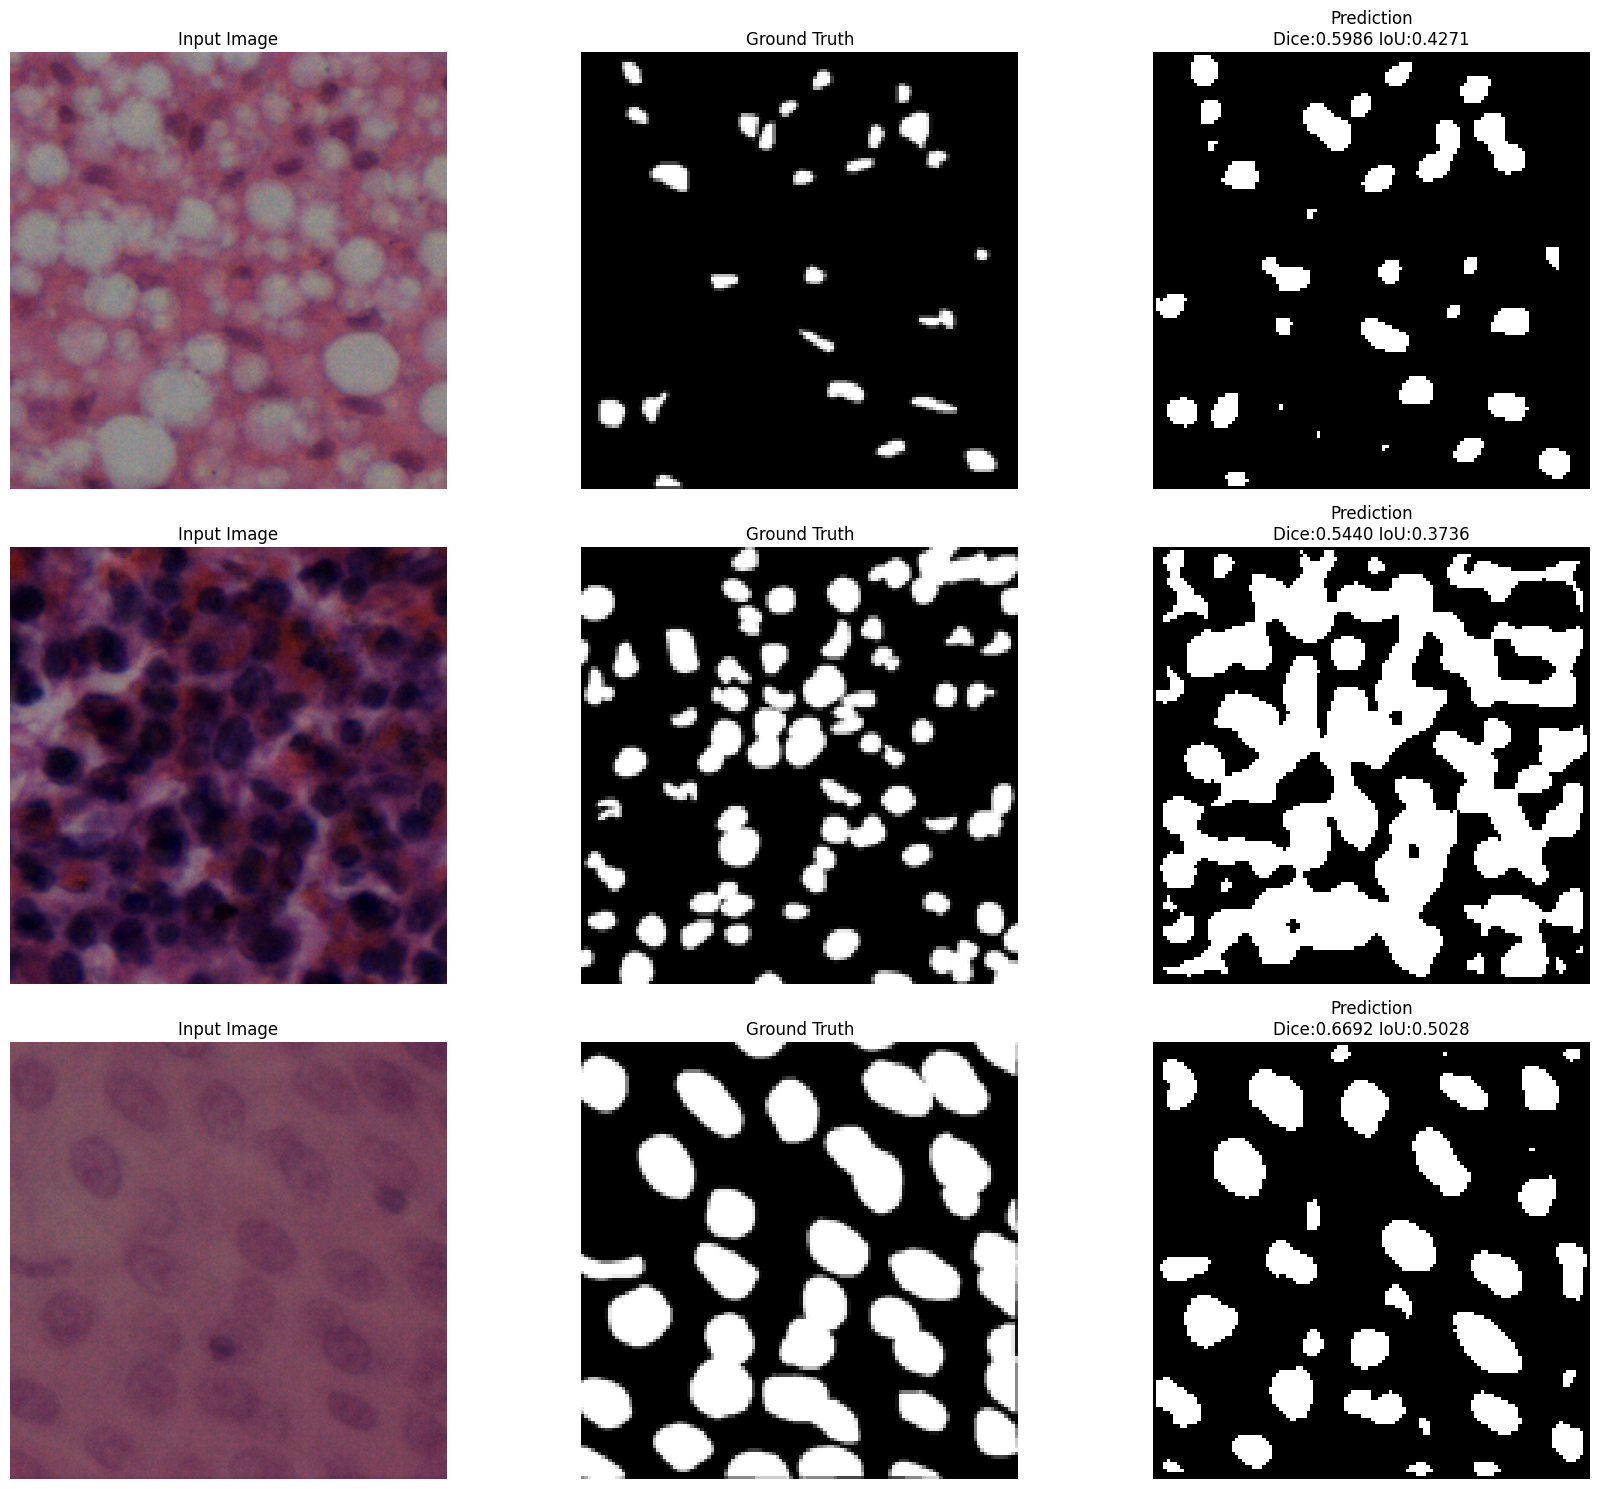

In [ ]:
# ============================================================
# UPDATED NUINSSEG U-NET++ PART 2
# ============================================================

import matplotlib.pyplot as plt

# ============================================================
# METRICS
# ============================================================

def dice_score(pred, target, smooth=1e-6):

    pred = torch.sigmoid(pred)
    pred = (pred > 0.6).float()

    intersection = (pred * target).sum(dim=(1,2,3))
    union = pred.sum(dim=(1,2,3)) + target.sum(dim=(1,2,3))

    dice = (2 * intersection + smooth) / (union + smooth)

    return dice.mean().item()


def iou_score(pred, target, smooth=1e-6):

    pred = torch.sigmoid(pred)
    pred = (pred > 0.6).float()

    intersection = (pred * target).sum(dim=(1,2,3))
    union = pred.sum(dim=(1,2,3)) + target.sum(dim=(1,2,3)) - intersection

    iou = (intersection + smooth) / (union + smooth)

    return iou.mean().item()

# ============================================================
# OPTIMIZER
# ============================================================

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=5e-5
)

best_dice = 0
best_iou = 0

EPOCHS = 50

# ============================================================
# TRAINING
# ============================================================

for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch+1}/{EPOCHS}")

    # ---------------- TRAIN ----------------
    model.train()
    train_loss = 0

    train_bar = tqdm(train_dl)

    for imgs, masks in train_bar:

        imgs = imgs.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(imgs)

        loss = criterion(outputs, masks)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

        train_bar.set_postfix(
            loss=loss.item()
        )

    avg_train_loss = train_loss / len(train_dl)

    # ---------------- VALIDATION ----------------
    model.eval()

    total_dice = 0
    total_iou = 0
    val_loss = 0

    with torch.no_grad():

        for imgs, masks in tqdm(val_dl):

            imgs = imgs.to(device)
            masks = masks.to(device)

            outputs = model(imgs)

            loss = criterion(outputs, masks)

            val_loss += loss.item()

            total_dice += dice_score(outputs, masks)
            total_iou += iou_score(outputs, masks)

    avg_val_loss = val_loss / len(val_dl)
    avg_dice = total_dice / len(val_dl)
    avg_iou = total_iou / len(val_dl)

    print(f"Train Loss : {avg_train_loss:.4f}")
    print(f"Val Loss   : {avg_val_loss:.4f}")
    print(f"Val Dice   : {avg_dice:.4f}")
    print(f"Val IoU    : {avg_iou:.4f}")

    if avg_dice > best_dice:
        best_dice = avg_dice
        best_iou = avg_iou

        torch.save(
            model.state_dict(),
            "/content/best_unetplusplus_nuinsseg.pth"
        )

        print("Best model saved!")

# ============================================================
# FINAL RESULTS
# ============================================================

print("\n" + "="*50)
print("FINAL BEST RESULTS")
print("="*50)

print(f"Best Dice Score : {best_dice:.4f}")
print(f"Best IoU Score  : {best_iou:.4f}")

# ============================================================
# COMPARISON TABLE
# ============================================================

print("\n" + "="*50)
print("COMPARISON TABLE")
print("="*50)

print(f"{'Model':<15} {'Dice':<10} {'IoU':<10}")
print("-"*40)
print(f"{'U-Net++':<15} {best_dice:<10.4f} {best_iou:<10.4f}")

# ============================================================
# VISUALIZATION
# ============================================================

print("\nGenerating sample predictions...")

model.load_state_dict(
    torch.load(
        "/content/best_unetplusplus_nuinsseg.pth",
        map_location=device
    )
)

model.eval()

num_samples = 3

indices = random.sample(
    range(len(val_imgs)),
    num_samples
)

plt.figure(figsize=(18, 5 * num_samples))

for i, idx in enumerate(indices):

    img_path = val_imgs[idx]
    mask_path = val_masks[idx]

    img_orig = Image.open(img_path).convert('RGB')
    mask_gt = Image.open(mask_path).convert('L')

    img_resized = img_orig.resize((128,128))
    gt_resized = mask_gt.resize((128,128))

    img_np = np.array(img_resized).astype('float32') / 255.0
    gt_np = np.array(gt_resized).astype('float32') / 255.0

    img_tensor = torch.tensor(
        img_np.transpose(2,0,1)
    ).unsqueeze(0).to(device)

    with torch.no_grad():
        pred = model(img_tensor)
        pred = torch.sigmoid(pred)[0,0].cpu().numpy()

    pred_bin = (pred > 0.6).astype(np.uint8)

    intersection = (pred_bin * gt_np).sum()

    sample_dice = (
        2 * intersection
    ) / (
        pred_bin.sum() + gt_np.sum() + 1e-6
    )

    sample_iou = (
        intersection
    ) / (
        pred_bin.sum() + gt_np.sum() - intersection + 1e-6
    )

    plt.subplot(num_samples, 3, i*3 + 1)
    plt.imshow(img_orig)
    plt.title("Input Image")
    plt.axis("off")

    plt.subplot(num_samples, 3, i*3 + 2)
    plt.imshow(gt_np, cmap='gray')
    plt.title("Ground Truth")
    plt.axis("off")

    plt.subplot(num_samples, 3, i*3 + 3)
    plt.imshow(pred_bin, cmap='gray')
    plt.title(
        f"Prediction\nDice:{sample_dice:.4f} IoU:{sample_iou:.4f}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()